# ERC circularité · 05 · Ligne de démontage et de tri

**Question** : faut-il installer une ligne de démontage et de tri des FRU rebutées ? Avec quelles pièces en réemploi, lesquelles en recyclage trié, et combien d'heures opérateur ?

**Décision éclairée** : installer ou non la ligne, la dimensionner en heures, choisir les types de FRU à traiter et les pièces à extraire.

**Principe du modèle** : chaque FRU rebuté reçoit un plan (une option par pièce : réemploi, recyclage trié, ou laissée dans le FRU). La ligne a un coût fixe (installation amortie, frais annuels) et une capacité en heures opérateur. Le modèle choisit les plans qui maximisent le gain par rapport à la situation actuelle, où tout part chez le recycleur actuel. La formulation (ensembles, paramètres, variables, objectif, contraintes, hypothèses) est dans [docs/Modele_mathematique.md](../docs/Modele_mathematique.md).

**Règle tenue partout** : un paramètre inconnu n'est jamais remplacé par zéro. L'option concernée reste « inconnue », et un type de FRU qu'on ne peut pas calculer est déclaré « incomplet » et sorti du calcul.

In [1]:
import sys
from pathlib import Path

# Le dossier est celui qui contient le code (erc/) : le parent de notebooks/.
dossier = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "erc" / "__init__.py").is_file()), Path.cwd().parent)
sys.path.insert(0, str(dossier))
import erc
from erc import affichage as aff

ctx = erc.executer(jusqua="ligne")

ERC circularité — DÉMONSTRATION (données fictives)


  étape sources       3 artefacts → artefacts/00_sources/


  étape classement   13 artefacts → artefacts/01_classement/


  étape flux         14 artefacts → artefacts/02_flux/


  étape fiabilite    11 artefacts → artefacts/03_fiabilite/


  étape rex          13 artefacts → artefacts/04_rex/


  étape ligne        17 artefacts → artefacts/05_ligne/


In [2]:
aff.etat(ctx)

DÉMONSTRATION : toutes les données affichées sont fictives. Période : du 01/06/2026 au 01/11/2026, 154 jours extraits. Aucune anomalie de calcul.

## 1. Paramètres et provenance

Chaque paramètre du modèle arrive avec sa provenance : **saisi** dans le classeur de paramètres, **tiré des données** (poids du classement matière, prix du référentiel des grades, MMICV, rebut annuel du suivi hebdomadaire, probabilité *q* du modèle de Rex), ou **manquant**.

**Lecture de la figure** : seuls les paramètres manquants *qui bloquent un calcul* (en orange) demandent une action ; les manquants facultatifs (transport, délai d'approvisionnement, valeur d'une semaine de délai) laissent simplement de côté le terme correspondant, et une ouverture sommaire non saisie est remplacée par l'ouverture soignée.

**Limite** : « saisi » ne veut pas dire « mesuré ». La colonne « Provenance » reprend la source notée dans le classeur, quand il y en a une ; en démonstration, toutes les valeurs sont fictives.

**Préparation des paramètres.** Où en est la collecte des paramètres du modèle : pour la ligne et pour chaque type de FRU, combien de paramètres sont saisis, tirés des données ou manquants. Lecture : seuls les segments orange empêchent un calcul ; ils désignent les données à obtenir en priorité.

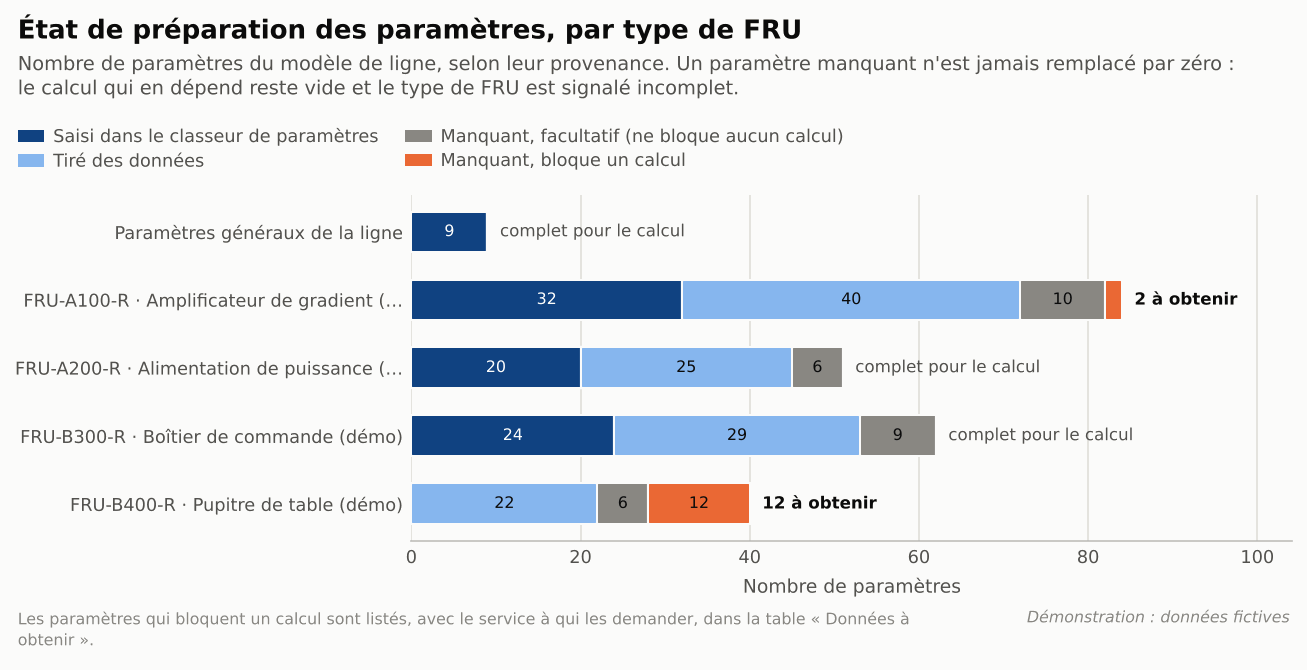

In [3]:
aff.figures(ctx, "ligne", "Préparation des paramètres")

Les paramètres généraux de la ligne, puis l'ensemble des paramètres (début de la table ; le fichier est complet) :

In [4]:
aff.table(ctx, "ligne", "Paramètres effectifs", ou={"FRU": "(ligne)"}, colonnes=["Paramètre", "Valeur", "Provenance", "État"])

Paramètre,Valeur,Provenance,État
cout_installation_eur,20000 | 30000 | 45000,saisi : DÉMO : valeur fictive,saisi
amortissement_ans,5,saisi : DÉMO : valeur fictive,saisi
couts_fixes_annuels_eur,6000,saisi : DÉMO : valeur fictive,saisi
heures_operateur_an,900,saisi : DÉMO : valeur fictive,saisi
taux_horaire_eur,38 | 42 | 48,saisi : DÉMO : valeur fictive,saisi
cout_traitement_eur_kg,"0,15 | 0,35",saisi : DÉMO : valeur fictive,saisi
valeur_reemploi_frac,"0,3 | 0,5 | 0,7",saisi : DÉMO : valeur fictive,saisi
valeur_semaine_eur,"0,5",saisi : DÉMO : valeur fictive,saisi
taux_change_mmicv,"0,92",saisi : DÉMO : valeur fictive,saisi


In [5]:
aff.table(ctx, "ligne", "Paramètres effectifs")

FRU,Pièce,Paramètre,Valeur,Provenance,État
(ligne),,cout_installation_eur,20000 | 30000 | 45000,saisi : DÉMO : valeur fictive,saisi
(ligne),,amortissement_ans,5,saisi : DÉMO : valeur fictive,saisi
(ligne),,couts_fixes_annuels_eur,6000,saisi : DÉMO : valeur fictive,saisi
(ligne),,heures_operateur_an,900,saisi : DÉMO : valeur fictive,saisi
(ligne),,taux_horaire_eur,38 | 42 | 48,saisi : DÉMO : valeur fictive,saisi
(ligne),,cout_traitement_eur_kg,"0,15 | 0,35",saisi : DÉMO : valeur fictive,saisi
(ligne),,valeur_reemploi_frac,"0,3 | 0,5 | 0,7",saisi : DÉMO : valeur fictive,saisi
(ligne),,valeur_semaine_eur,"0,5",saisi : DÉMO : valeur fictive,saisi
(ligne),,taux_change_mmicv,"0,92",saisi : DÉMO : valeur fictive,saisi
FRU-A100-R,,rebut_an,"243,455 | 312 | 378,182",auto : suivi hebdomadaire (22 semaines complètes),tiré des données


## 2. Données à obtenir

Ce qui manque pour calculer, regroupé par paramètre, avec le service à qui le demander. Seuls les paramètres qui bloquent un calcul sont listés.

**Décision éclairée** : le contenu de l'audit de démontage chronométré (temps d'ouverture, d'extraction, de test, de tri), les pesées et les consultations de recycleurs à lancer.

In [6]:
aff.table(ctx, "ligne", "Données à obtenir")

Paramètre,Donnée,Valeurs manquantes,FRU concernés,À demander à
tri_min,Tri d'un exemplaire vers son flux de recyclage (minutes),4,1,Audit de démontage chronométré
test_min,Test d'un exemplaire (minutes),3,1,"Audit de démontage chronométré, qualité"
extraction_min,Extraction d'un exemplaire (minutes),3,1,Audit de démontage chronométré
poids_kg,Poids d'un exemplaire (vide = classement matière),1,1,Pesée
ouverture_min,"Ouverture soignée du FRU, pour extraire des pièces à réemployer (minutes)",1,1,Audit de démontage chronométré
prix_recycleur_eur_kg,Prix payé par le recycleur acheteur (vide = référentiel des grades),1,1,Consultation des recycleurs
valeur_eur,Valeur d'une pièce réemployée (vide = MMICV × fraction de la ligne),1,1,Finance supply chain


## 3. Les trois options, pièce par pièce

Valeur nette **par FRU traité** de chaque option, comparée à la pièce laissée dans le FRU (option 3, valeur zéro) :

- **Réemploi** : probabilité *q* × (valeur de la pièce + délai d'approvisionnement évité) + valeur au kilo des pièces qui échouent au test − transport − main-d'œuvre d'extraction et de test, + traitement évité chez le recycleur actuel ;
- **Recyclage trié** : poids × prix du recycleur acheteur − main-d'œuvre de tri, + traitement évité ;
- **Laissée dans le FRU** : zéro, c'est la référence.

L'ouverture du FRU est payée **une seule fois par FRU**, quel que soit le nombre de pièces extraites : elle n'est pas dans ces valeurs, elle est indiquée dans le titre de chaque cadre. C'est pourquoi une pièce peu rentable seule peut le devenir à côté d'une autre.

**Lecture** : une barre à droite du zéro rapporte, à gauche elle coûte. « inconnu » signifie qu'une donnée manque : son nom est celui de la colonne du classeur de paramètres à remplir. La valeur n'est pas calculée et l'option n'est jamais choisie. Dans la table, la colonne « Non compté faute de donnée » dit ce que la valeur du réemploi laisse de côté (transport, délai évité) parce qu'une donnée facultative n'est pas saisie.

**Limites** : la valeur d'une pièce réemployée est une fraction du MMICV, pas un prix constaté ; *q* vient du modèle de Rex. Ce sont des estimations.

**Options par pièce.** Pour chaque pièce de chaque type de FRU : ce que rapporte le réemploi (bleu) et ce que rapporte le recyclage trié (orange), par FRU traité, comparés à la pièce laissée dans le FRU. Une option dont une donnée manque est écrite « inconnu », jamais tracée à zéro.

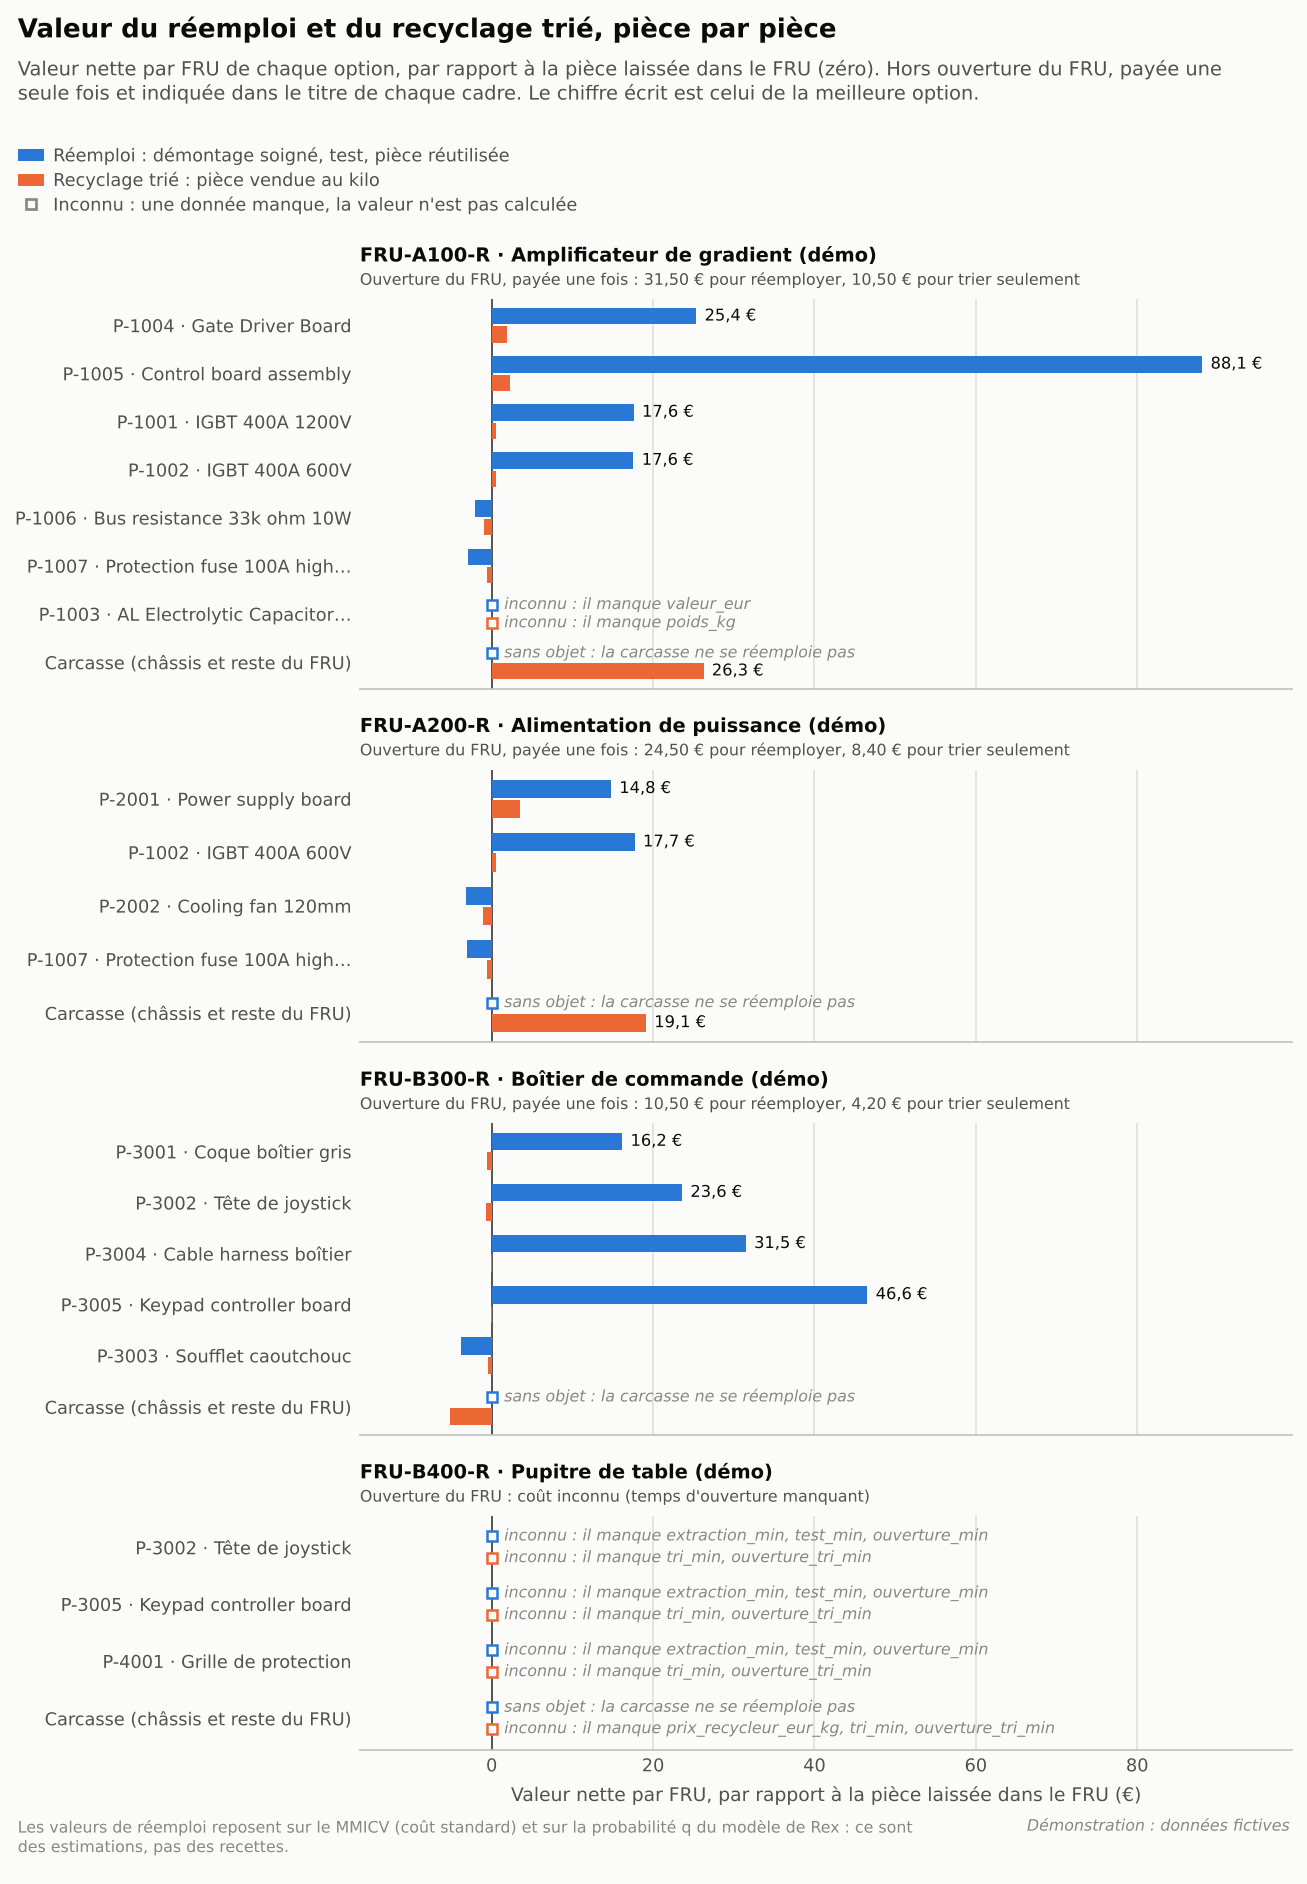

In [7]:
aff.figures(ctx, "ligne", "Options par pièce")

In [8]:
aff.table(ctx, "ligne", "Options par pièce", colonnes=["Type de FRU", "Pièce", "1 Réemploi (€/FRU)", "2 Recyclage (€/FRU)", "3 Jeté (€/FRU)", "Heures réemploi",
          "Heures recyclage", "Manque réemploi", "Manque recyclage", "Non compté faute de donnée", "Ouverture soignée (€/FRU)", "Ouverture sommaire (€/FRU)"])

Type de FRU,Pièce,1 Réemploi (€/FRU),2 Recyclage (€/FRU),3 Jeté (€/FRU),Heures réemploi,Heures recyclage,Manque réemploi,Manque recyclage,Non compté faute de donnée,Ouverture soignée (€/FRU),Ouverture sommaire (€/FRU)
FRU-A100-R,P-1004,"25,35","1,90",0,"0,500","0,033",,,transport,"31,50","10,50"
FRU-A100-R,P-1005,"88,06","2,31",0,"0,500","0,033",,,transport,"31,50","10,50"
FRU-A100-R,P-1001,"17,60","0,53",0,"0,333","0,033",,,transport,"31,50","10,50"
FRU-A100-R,P-1002,"17,57","0,53",0,"0,333","0,033",,,transport,"31,50","10,50"
FRU-A100-R,P-1006,"−2,03","−0,94",0,"0,150","0,025",,,"transport, délai évité","31,50","10,50"
FRU-A100-R,P-1007,"−2,93","−0,58",0,"0,100","0,017",,,"transport, délai évité","31,50","10,50"
FRU-A100-R,P-1003,,,0,,,valeur_eur,poids_kg,,"31,50","10,50"
FRU-A100-R,CARCASSE,,"26,25",0,,"0,167","extraction_min, test_min, p_reutilisable, valeur_eur",,,"31,50","10,50"
FRU-A200-R,P-2001,"14,78","3,55",0,"0,533","0,033",,,transport,"24,50","8,40"
FRU-A200-R,P-1002,"17,72","0,53",0,"0,333","0,033",,,transport,"24,50","8,40"


## 4. Le plan optimal

Pour chaque type de FRU : traiter ou laisser, quelles pièces réemployer, lesquelles recycler, combien d'heures et quelle marge. Quand les heures manquent, le modèle sert d'abord les plans qui rapportent le plus par heure ; un type de FRU peut alors apparaître sur deux lignes (une partie du flux avec un plan complet, le reste avec un plan plus court).

**Lecture du résumé** : le résultat annuel est la marge variable moins les coûts fixes annualisés. Le *seuil de rentabilité* est le nombre de FRU à traiter par an pour couvrir les coûts fixes. La *valeur d'une heure opérateur en plus* est ce que rapporterait une heure supplémentaire : zéro si la capacité n'est pas saturée.

**Limites** : calcul au centre des plages de paramètres (l'incertitude est traitée en section 7) ; les types de FRU incomplets sont exclus, ce qui sous-estime le gisement.

In [9]:
aff.table(ctx, "ligne", "Plan optimal", colonnes=["Type de FRU", "Décision", "1 Réemploi", "2 Recyclage", "FRU traitées / an", "FRU rebutées / an", "Heures par FRU",
          "Marge par FRU (€)", "Marge par heure (€)", "Heures / an", "Marge variable / an (€)", "Kg détournés / an"])

Type de FRU,Décision,1 Réemploi,2 Recyclage,FRU traitées / an,FRU rebutées / an,Heures par FRU,Marge par FRU (€),Marge par heure (€),Heures / an,Marge variable / an (€),Kg détournés / an
FRU-A100-R,traiter,"P-1005, P-1004, P-1001, P-1002",CARCASSE,"290,6","312,0","2,58","143,3","55,48","750,6",41 646,22 865
FRU-A100-R,traiter,"P-1005, P-1001, P-1002","CARCASSE, P-1004","21,4","312,0","2,12","119,9","56,63","45,4",2 569,1 686
FRU-A200-R,jeter telle quelle,,,"0,0","115,8","0,00","0,0",,"0,0",0,0
FRU-B300-R,traiter,"P-3005, P-3004, P-3002, P-3001",,"94,5","94,5","1,10","107,3","97,56","104,0",10 146,113
FRU-B400-R,incomplet,,,,,,,,,,


Les types de FRU **incomplets**, avec ce qui manque pour les calculer (nom des paramètres du classeur) :

In [10]:
aff.table(ctx, "ligne", "Plan optimal", ou={"Décision": "incomplet"}, colonnes=["Type de FRU", "Entrées manquantes"])

Type de FRU,Entrées manquantes
FRU-B400-R,"aucune option calculable : P-3002 réemploi[extraction_min, test_min, ouverture_min] recyclage[tri_min, ouverture_tri_min]; P-3005 réemploi[extraction_min, test_min, ouverture_min] recyclage[tri_min, ouverture_tri_min]; P-4001 réemploi[extraction_min, test_min, ouverture_min] recyclage[tri_min, ouverture_tri_min]; CARCASSE réemploi[extraction_min, test_min, p_reutilisable, valeur_eur, ouverture_min] recyclage[prix_recycleur_eur_kg, tri_min, ouverture_tri_min]"


Le résumé de la ligne au centre des plages :

In [11]:
aff.table(ctx, "ligne", "Résumé")

Indicateur,Valeur
Marge variable / an (€),54 361
Coûts fixes annualisés (€),12 000
Résultat / an (€),42 361
Heures utilisées / an,900
Capacité (h/an),900
Taux d'occupation,1
FRU traitées / an,"406,5"
Marge moyenne par FRU (€),"133,7"
Seuil de rentabilité (FRU / an),"89,74"
Retour sur investissement (ans),"0,620"


## 5. Situation actuelle contre ligne

Flux annuels en euros, coût en négatif. La situation actuelle se résume au traitement de tous les FRU rebutés par le recycleur actuel. Avec la ligne s'ajoutent la marge de la ligne et ses coûts fixes, et le traitement résiduel diminue.

**Lecture** : la ligne « TOTAL », colonne « Écart », est le gain annuel attendu de la ligne.

**Limite** : le coût de traitement actuel repose sur un prix au kilo saisi et sur le poids des FRU ; si l'un des deux manque, le poste et le total restent vides.

**Actuel contre ligne.** Le coût annuel de la situation actuelle (tous les FRU rebutés partent chez le recycleur actuel) comparé au bilan avec la ligne, poste par poste puis au total. Lecture : l'écart entre les deux barres du total est le gain annuel attendu de la ligne.

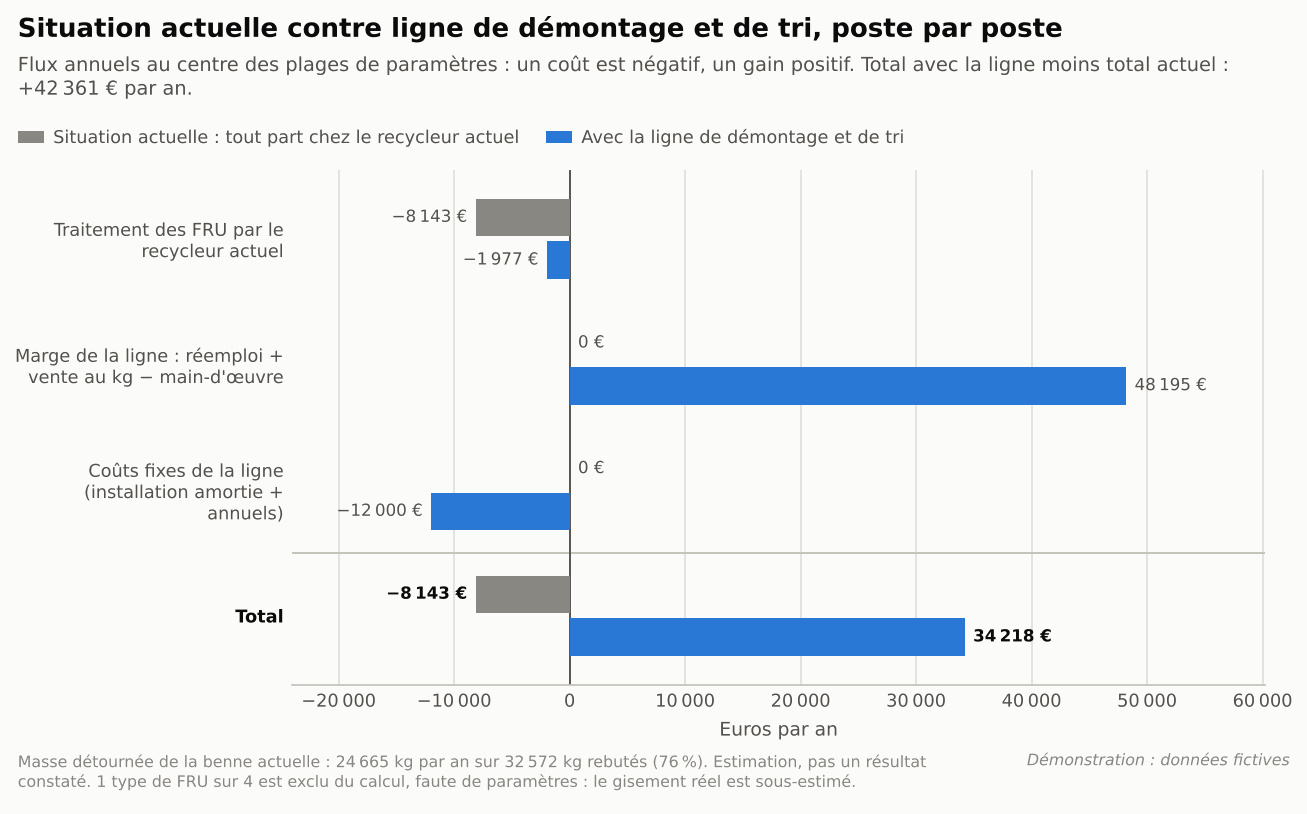

In [12]:
aff.figures(ctx, "ligne", "Actuel contre ligne")

In [13]:
aff.table(ctx, "ligne", "Actuel contre ligne")

Poste (€/an),Actuel,Avec la ligne,Écart
Traitement des FRU par le recycleur actuel,−8 143,−1 977,6 166
Marge de la ligne : réemploi + vente au kg − main-d'œuvre,0,48 195,48 195
Coûts fixes de la ligne (installation amortie + annuels),0,−12 000,−12 000
TOTAL,−8 143,34 218,42 361


## 6. Semaine par semaine

Le modèle est rejoué sur le flux réel de chaque semaine : capacité et coût fixe de la semaine, pas de stock d'une semaine à l'autre.

**Lecture** : les semaines creuses paient le coût fixe sans marge ; les semaines chargées saturent les heures et laissent des FRU. L'écart entre ce résultat annualisé et celui du modèle annuel au flux moyen est le **coût de l'irrégularité du flux** : c'est, au plus, ce que rapporterait un stock tampon de FRU en attente.

**Limite** : l'hypothèse « pas de stock » est pessimiste si l'atelier peut garder des FRU quelques semaines.

**Semaine par semaine.** En haut, le résultat de chaque semaine : la marge dégagée sur les FRU arrivés cette semaine-là, moins le coût fixe hebdomadaire. En bas, le cumul. Lecture : les semaines creuses coûtent le coût fixe ; les semaines chargées saturent les heures disponibles.

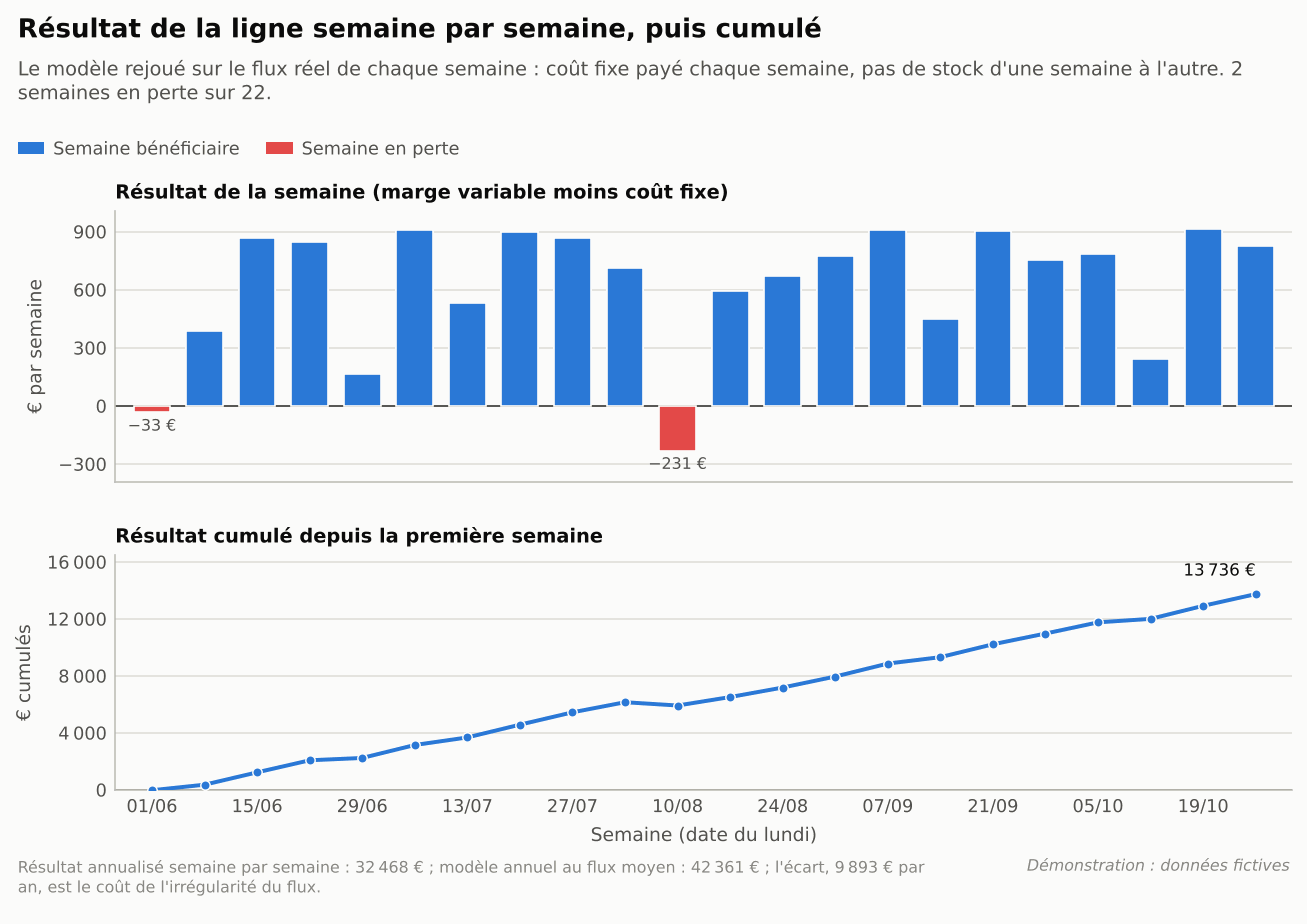

In [14]:
aff.figures(ctx, "ligne", "Semaine par semaine")

In [15]:
aff.table(ctx, "ligne", "Période par période")

Semaine,FRU arrivées,FRU traitées,Heures utilisées,Capacité (h),Marge variable (€),Coût fixe (€),Résultat (€),Valeur d'une heure en plus (€),Résultat cumulé (€)
01/06/2026,3,"3,00","5,82","17,31",198,"230,8","−33,2","0,00",−33
08/06/2026,8,"7,00","13,70","17,31",619,"230,8","387,9","0,00",355
15/06/2026,17,"12,66","17,31","17,31",1 098,"230,8","866,9","58,45",1 222
22/06/2026,11,"10,00","17,31","17,31",1 077,"230,8","846,6","52,70",2 068
29/06/2026,3,"3,00","6,27","17,31",394,"230,8","163,2","0,00",2 231
06/07/2026,19,"12,89","17,31","17,31",1 141,"230,8","910,0","58,45",3 141
13/07/2026,9,"8,00","16,28","17,31",762,"230,8","531,2","0,00",3 673
20/07/2026,16,"11,00","17,31","17,31",1 127,"230,8","896,0","52,80",4 569
27/07/2026,17,"12,66","17,31","17,31",1 098,"230,8","866,9","58,45",5 436
03/08/2026,10,"10,00","17,00","17,31",941,"230,8","709,8","0,00",6 145


## 7. Incertitude : tirages de Monte-Carlo

Chaque paramètre saisi comme une plage est tiré au hasard dans sa plage, et la ligne est ré-optimisée à chaque tirage.

**Lecture** : P5 et P95 encadrent neuf tirages sur dix ; la part des tirages à droite de zéro estime la probabilité que la ligne soit rentable, pour les plages saisies.

**Limites** : le résultat ne vaut que ce que valent les plages saisies. Un paramètre saisi comme une valeur unique est traité comme certain. Des plages trop étroites donnent une assurance qui n'existe pas.

**Monte-Carlo.** Ce que devient le résultat annuel quand tous les paramètres incertains varient dans leurs plages. Lecture : P5 et P95 encadrent neuf tirages sur dix ; la part de la distribution à gauche de zéro est le risque que la ligne ne soit pas rentable.

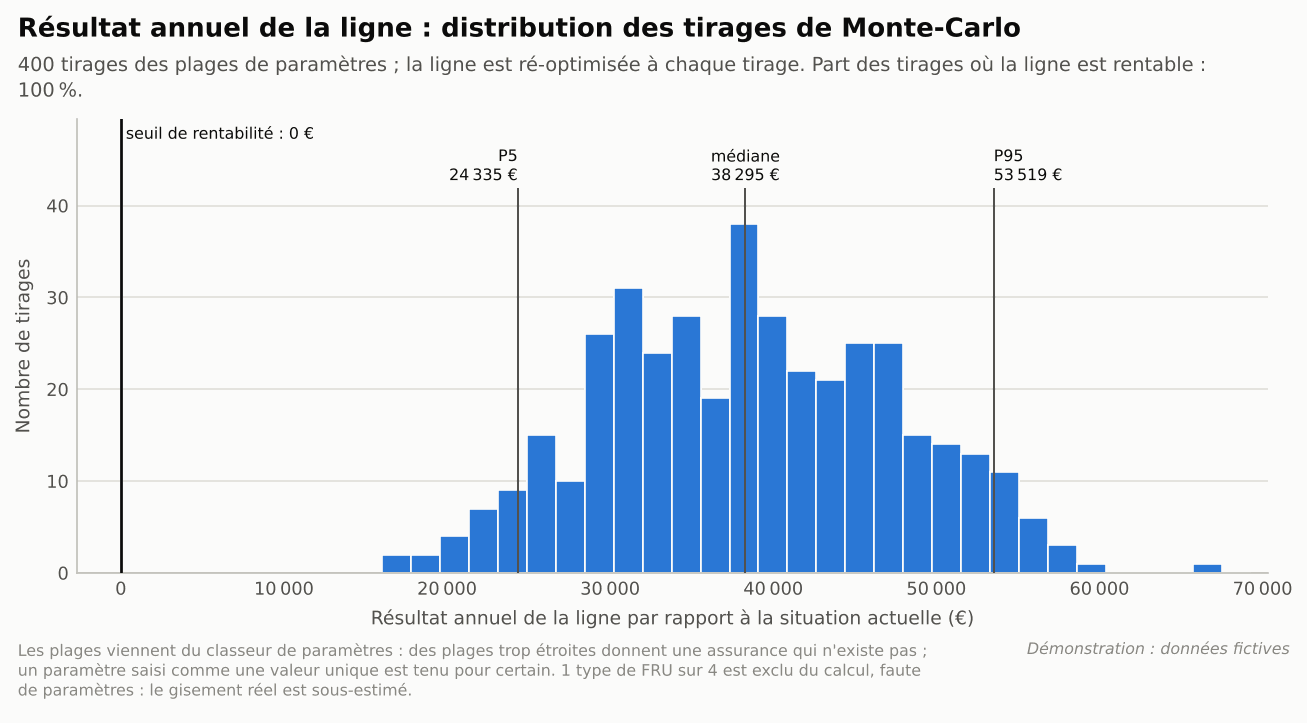

In [16]:
aff.figures(ctx, "ligne", "Monte-Carlo")

In [17]:
aff.table(ctx, "ligne", "Monte-Carlo (tirages)", n=5)

Résultat / an (€),Marge variable / an (€),Heures utilisées / an,FRU traitées / an
53 517,64 855,"900,0","397,9"
46 900,59 148,"893,5","518,5"
29 796,42 367,"900,0","536,8"
38 096,51 191,"900,0","549,5"
35 122,46 743,"900,0","369,6"


## 8. Sensibilité aux heures opérateur

Le modèle est recalculé pour plusieurs niveaux d'heures disponibles, du quart au triple de la capacité saisie.

**Décision éclairée** : combien d'heures demander. Tant que le résultat monte, les heures manquent ; quand il plafonne, tous les FRU rentables sont déjà traités et une heure de plus ne rapporte rien.

**Sensibilité aux heures.** En haut, le résultat annuel selon les heures opérateur accordées à la ligne ; en bas, ce que rapporterait une heure de plus. Lecture : tant que la courbe du haut monte, les heures manquent ; quand elle plafonne, ajouter des heures ne rapporte plus rien.

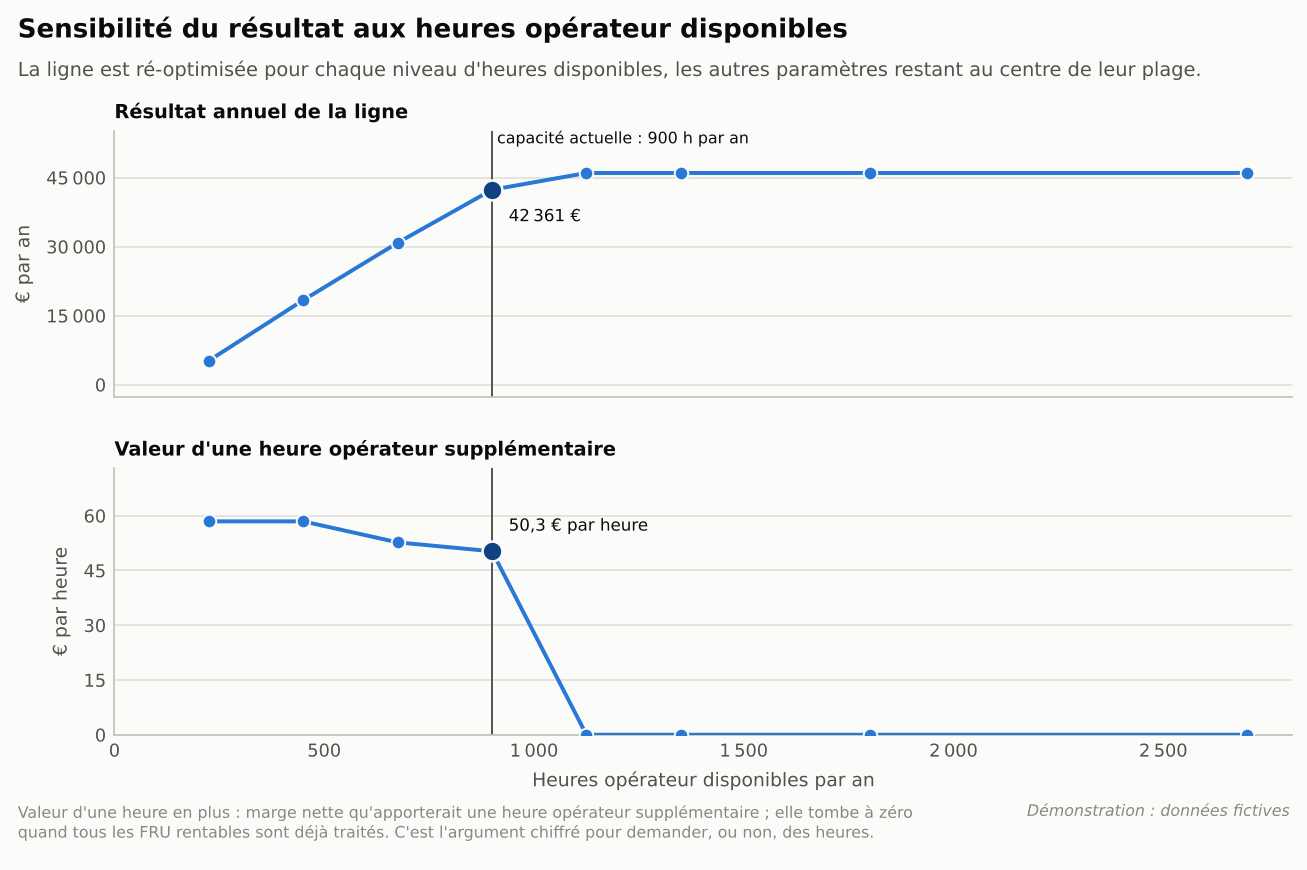

In [18]:
aff.figures(ctx, "ligne", "Sensibilité aux heures")

In [19]:
aff.table(ctx, "ligne", "Sensibilité aux heures")

Heures / an,Marge variable / an (€),Résultat / an (€),Taux d'occupation,FRU traitées / an,Valeur d'une heure opérateur en plus (€ net)
225,17 219,5 219,"100,0 %","180,0","58,45"
450,30 370,18 370,"100,0 %","338,8","58,45"
675,42 835,30 835,"100,0 %","406,5","52,70"
900,54 361,42 361,"100,0 %","406,5","50,25"
1 125,58 005,46 005,"97,5 %","522,4","0,00"
1 350,58 005,46 005,"81,3 %","522,4","0,00"
1 800,58 005,46 005,"61,0 %","522,4","0,00"
2 700,58 005,46 005,"40,6 %","522,4","0,00"


## Notes de l'étape

Les indicateurs du résumé, du comparatif, du calcul semaine par semaine et du Monte-Carlo, tels qu'ils sont repris par la synthèse et par l'outil des décideurs.

In [20]:
aff.notes(ctx, "ligne")

Élément,Valeur
Résumé › Marge variable / an (€),54 361
Résumé › Coûts fixes annualisés (€),12 000
Résumé › Résultat / an (€),42 361
Résumé › Heures utilisées / an,900
Résumé › Capacité (h/an),900
Résumé › Taux d'occupation,"100,0 %"
Résumé › FRU traitées / an,"406,5"
Résumé › Marge moyenne par FRU (€),"133,7"
Résumé › Seuil de rentabilité (FRU / an),"89,74"
Résumé › Retour sur investissement (ans),"0,62"


---
Notebook suivant : **06_Synthese_decideurs**. Tous les fichiers affichés ici sont dans le dossier des artefacts, étape `05_ligne` ; un classeur Excel du même nom réunit les tables de l'étape.